# Plotting & 3D Visualisation

Cheetah provides several utilities for plotting beam parameters and visualising accelerator lattices in 2D and 3D.


## 2D Plotting of Beam Parameters

Cheetah can compute and plot Twiss parameters and beam statistics (like centroids or envelope sizes) along the length of a `Segment`.

First, let's define a simple lattice segment and an incoming beam:


In [1]:
import torch
import cheetah

# Define a simple lattice segment
segment = cheetah.Segment(
    elements=[
        cheetah.Drift(length=torch.tensor(0.5)),
        cheetah.Quadrupole(length=torch.tensor(0.1), k1=torch.tensor(4.2), name="Q1"),
        cheetah.Drift(length=torch.tensor(0.5)),
        cheetah.Quadrupole(length=torch.tensor(0.1), k1=torch.tensor(-4.2), name="Q2"),
        cheetah.Drift(length=torch.tensor(0.5)),
        cheetah.Screen(name="Screen"),
    ]
)

# Define incoming beam
incoming_beam = cheetah.ParameterBeam.from_twiss(
    beta_x=torch.tensor(3.14), beta_y=torch.tensor(3.14), energy=torch.tensor(1e7)
)

### Tracking Attributes Along a Segment

To compute beam properties at every step along the lattice, use the `get_beam_attrs_along_segment` method:


In [2]:
# Returns positions (s) and computed attributes along the lattice
s, x_envelope, y_envelope = segment.get_beam_attrs_along_segment(
    ("s", "sigma_x", "sigma_y"), incoming_beam
)
print("Positions (s):", s)
print("sigma_x envelope:", x_envelope)

Positions (s): tensor([0.0000, 0.5000, 0.6000, 1.1000, 1.2000, 1.7000, 1.7000])
sigma_x envelope: tensor([1.5033e-06, 1.5222e-06, 1.4986e-06, 1.2487e-06, 1.2317e-06, 1.3158e-06,
        1.3158e-06])


### Plotting Twiss Parameters

To plot the horizontal ($\beta_x$) and vertical ($\beta_y$) beta functions along the lattice:


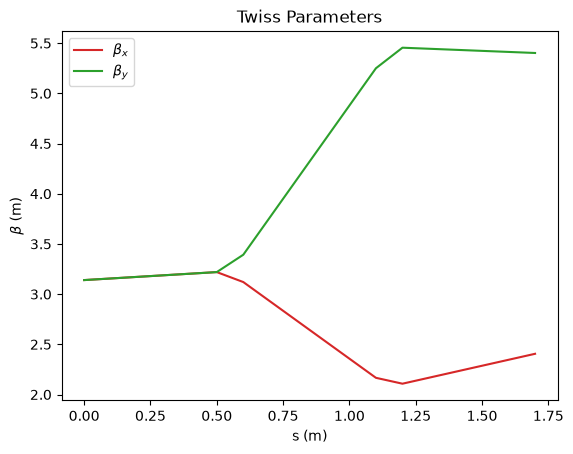

In [3]:
# Plot Twiss parameters directly
ax = segment.plot_twiss(incoming_beam)

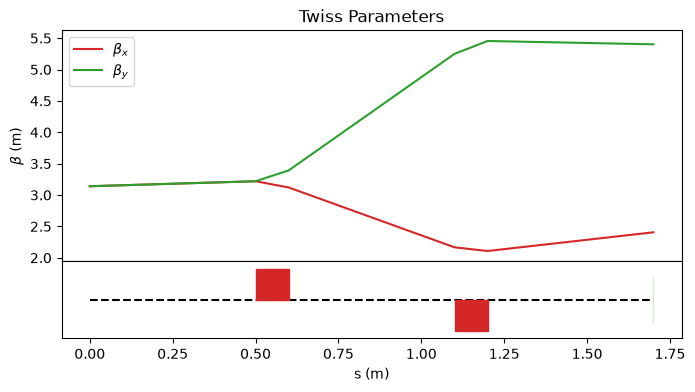

In [4]:
# Or plot Twiss parameters with the lattice layout aligned underneath
fig = segment.plot_twiss_over_lattice(incoming_beam)

### Plotting Beam Attributes

To plot general statistics (e.g. centroids `mu_x`, `mu_y` or envelopes `sigma_x`, `sigma_y`):


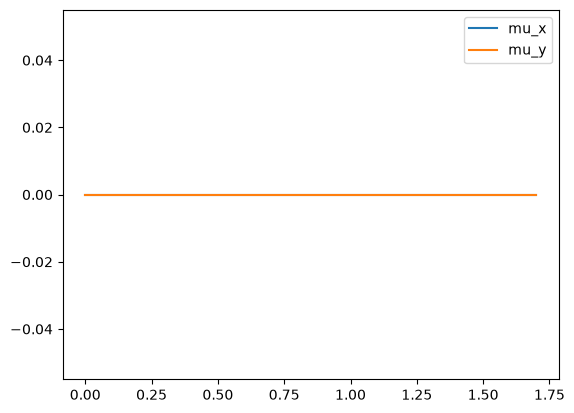

In [5]:
# Plot centroids
ax = segment.plot_beam_attrs(incoming_beam, ("mu_x", "mu_y"))

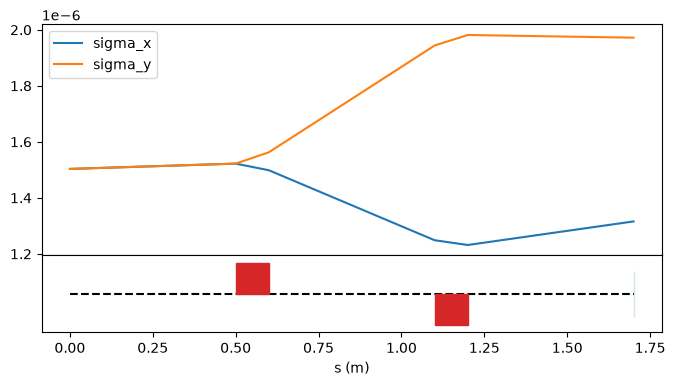

In [6]:
# Plot envelopes over the lattice layout
fig = segment.plot_beam_attrs_over_lattice(incoming_beam, ("sigma_x", "sigma_y"))

### Quick Overview Plots

Use `plot_overview` to plot a standard summary of the beam centroids, standard deviations, and reference particle traces along the lattice:


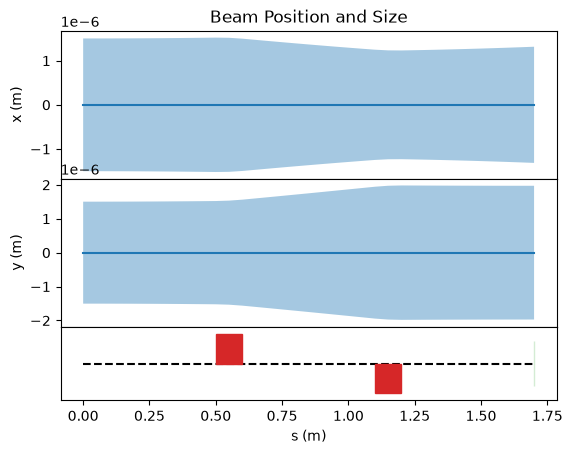

In [7]:
fig = segment.plot_overview(incoming=incoming_beam, resolution=0.05)

Use `plot_mean_and_std` for a simpler plot of the centroid position accompanied by shaded bands representing the standard deviation:


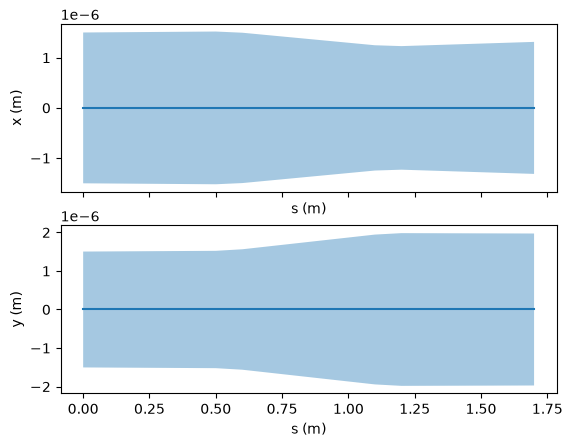

In [8]:
axx, axy = segment.plot_mean_and_std(incoming_beam)

### Interactive 3D Phase Space Bunch Visualisation

In addition to 2D projections, we can inspect the 3D phase space structure of a particle bunch $ interactively with Plotly:


In [9]:
import plotly.graph_objects as go

# Extract particle coordinates
x = incoming_beam.particles[:, 0].detach().cpu().numpy() * 1e3  # mm
y = incoming_beam.particles[:, 2].detach().cpu().numpy() * 1e3  # mm
tau = incoming_beam.particles[:, 4].detach().cpu().numpy() * 1e6  # μm
delta = incoming_beam.particles[:, 5].detach().cpu().numpy() * 1e3  # 10⁻³

fig = go.Figure(
    data=[
        go.Scatter3d(
            x=tau,
            y=x,
            z=y,
            mode="markers",
            marker=dict(
                size=2.5,
                color=delta,
                colorscale="Viridis",
                colorbar=dict(title="δ (10⁻³)"),
                opacity=0.7,
            ),
        )
    ]
)
fig.update_layout(
    title="Interactive 3D Particle Bunch (τ, x, y)",
    scene=dict(
        xaxis_title="Longitudinal τ (μm)",
        yaxis_title="Horizontal x (mm)",
        zaxis_title="Vertical y (mm)",
    ),
    margin=dict(l=0, r=0, b=0, t=40),
    height=480,
)
fig.show()


---

## 3D Visualisation

Cheetah allows you to generate a 3D 3D model mesh of your lattice. This can be viewed interactively or exported to standard formats like GLB/gltf.


### Installation Prerequisite

3D visualisation requires additional dependencies. Install Cheetah with the `[3d-visualization]` extra:

```bash
pip install "cheetah-accelerator[3d-visualization]"
```


### Generating and Exporting a Mesh

Use the `to_mesh` method on a `Segment` to generate a 3D mesh. We can export the generated mesh to a GLB file:


In [9]:
# Generate 3D mesh
mesh, _ = segment.to_mesh(
    cuteness={cheetah.HorizontalCorrector: 2.0, cheetah.VerticalCorrector: 2.0}
)

# Export to a binary GLB file
mesh.export("ares_lattice.glb", file_type="glb")


In [10]:
from IPython.display import HTML

# Display interactive 3D model viewer
HTML("""<model-viewer
    src="../_static/ares_lattice.glb"
    alt="3D Interactive Accelerator Lattice"
    auto-rotate
    camera-controls
    shadow-intensity="1"
    exposure="1"
    style="width: 100%; height: 450px; border-radius: 8px;">
</model-viewer>
<p style="text-align: center; font-size: 0.85em; color: gray; margin-top: 6px;">
    <em>Interactive 3D lattice: click and drag to orbit, scroll to zoom, right-click to pan.</em>
</p>""")


Interactive 3D lattice: click and drag to orbit, scroll to zoom, right-click to pan.